# SentinelX AI — S2 : analyse exploratoire et préparation des données

**NASA C-MAPSS FD001.** Objectif : comprendre les données, choisir les capteurs utiles, construire la cible RUL et séparer les moteurs avant la baseline (S3).

Les décisions prises ici sont exportées dans `artifacts/eda_fd001/` et relues par le notebook de baseline.
`RUL_FD001.txt` (vérité du test) n'est **jamais lu** dans ce notebook.

## 1. Préparation

In [1]:
from pathlib import Path
import hashlib
import json
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

ROOT = Path(".") if Path("data/raw").exists() else Path("..")   # lancé depuis la racine ou depuis notebooks/
sys.path.insert(0, str(ROOT.resolve()))
from ml.src.data import COLUMN_NAMES, add_rul, load_cmapss, split_engines

RAW_DIR = ROOT / "data" / "raw"
OUT_DIR = ROOT / "artifacts" / "eda_fd001"
FIG_DIR = OUT_DIR / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)

RANDOM_STATE = 42
N_VALIDATION_ENGINES = 20
sns.set_theme(style="whitegrid")
pd.set_option("display.precision", 3)


def save(fig, name):
    fig.savefig(FIG_DIR / name, dpi=120, bbox_inches="tight")
    plt.show()

## 2. Chargement

Chaque ligne décrit un moteur à un cycle : `unit_id`, `cycle`, 3 réglages (`setting_1..3`) et 21 capteurs anonymes (`sensor_1..21`).
L'empreinte SHA-256 garantit que les fichiers sont bien les fichiers NASA d'origine.

In [2]:
train_df = load_cmapss(RAW_DIR / "train_FD001.txt")
test_df = load_cmapss(RAW_DIR / "test_FD001.txt")
sha256 = {name: hashlib.sha256((RAW_DIR / name).read_bytes()).hexdigest()
          for name in ["train_FD001.txt", "test_FD001.txt"]}

print("Train :", train_df.shape, "-", train_df["unit_id"].nunique(), "moteurs")
print("Test  :", test_df.shape, "-", test_df["unit_id"].nunique(), "moteurs")
print(sha256)
train_df.head()

Train : (20631, 26) - 100 moteurs
Test  : (13096, 26) - 100 moteurs
{'train_FD001.txt': '963b5e22825b34d8b21c69e1aeb4af3e647050eb672ee8834ba4b5d91d2de0f8', 'test_FD001.txt': '3cda7109ce17bafb5443f2ac926cfcf88154b941b8c4cf95eb55d1ddd6f52851'}


,unit_id,cycle,setting_1,setting_2,setting_3,sensor_1,sensor_2,sensor_3,sensor_4,sensor_5,...,sensor_12,sensor_13,sensor_14,sensor_15,sensor_16,sensor_17,sensor_18,sensor_19,sensor_20,sensor_21
0,1,1,-7.000e-04,-4.000e-04,100.0,518.67,641.82,1589.70,1400.60,14.62,...,521.66,2388.02,8138.62,8.419,0.03,392,2388,100.0,39.06,23.419
1,1,2,1.900e-03,-3.000e-04,100.0,518.67,642.15,1591.82,1403.14,14.62,...,522.28,2388.07,8131.49,8.432,0.03,392,2388,100.0,39.00,23.424
2,1,3,-4.300e-03,3.000e-04,100.0,518.67,642.35,1587.99,1404.20,14.62,...,522.42,2388.03,8133.23,8.418,0.03,390,2388,100.0,38.95,23.344
3,1,4,7.000e-04,0.000e+00,100.0,518.67,642.35,1582.79,1401.87,14.62,...,522.86,2388.08,8133.83,8.368,0.03,392,2388,100.0,38.88,23.374
4,1,5,-1.900e-03,-2.000e-04,100.0,518.67,642.37,1582.85,1406.22,14.62,...,522.19,2388.04,8133.80,8.429,0.03,393,2388,100.0,38.90,23.404


## 3. Qualité des données

Valeurs manquantes, doublons, continuité des cycles et premier cycle de chaque moteur. Une erreur ici fausserait directement le calcul du RUL.

In [3]:
quality = {
    "valeurs manquantes": int(train_df.isna().sum().sum()),
    "lignes en double": int(train_df.duplicated().sum()),
    "doublons (moteur, cycle)": int(train_df.duplicated(["unit_id", "cycle"]).sum()),
    "trous dans les cycles": int((train_df.groupby("unit_id")["cycle"].diff().dropna() != 1).sum()),
    "moteurs ne commençant pas au cycle 1": int((train_df.groupby("unit_id")["cycle"].min() != 1).sum()),
}
quality

{'valeurs manquantes': 0,
 'lignes en double': 0,
 'doublons (moteur, cycle)': 0,
 'trous dans les cycles': 0,
 'moteurs ne commençant pas au cycle 1': 0}

**Résultat.** Toutes les vérifications valent 0 : aucune correction ni imputation n'est nécessaire.

## 4. Durée de vie des moteurs

{'count': 100.0, 'mean': 206.3, 'std': 46.3, 'min': 128.0, '25%': 177.0, '50%': 199.0, '75%': 229.2, 'max': 362.0}


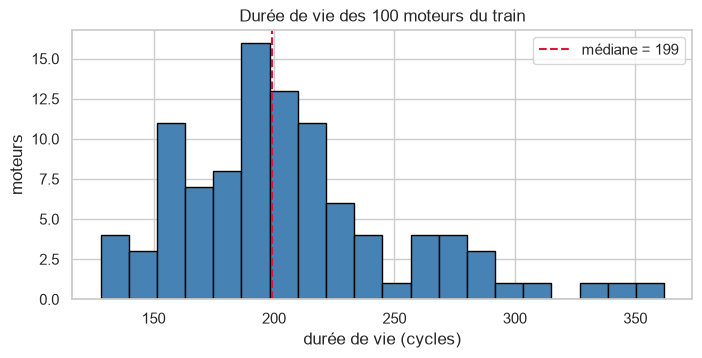

Moteurs > 300 cycles : [67, 69, 92, 96]


In [4]:
train_lengths = train_df.groupby("unit_id")["cycle"].max()
print(train_lengths.describe().round(1).to_dict())

fig, ax = plt.subplots(figsize=(8, 3.5))
ax.hist(train_lengths, bins=20, color="steelblue", edgecolor="black")
ax.axvline(train_lengths.median(), color="crimson", linestyle="--", label=f"médiane = {train_lengths.median():.0f}")
ax.set(xlabel="durée de vie (cycles)", ylabel="moteurs", title="Durée de vie des 100 moteurs du train")
ax.legend()
save(fig, "01_duree_de_vie.png")
print("Moteurs > 300 cycles :", train_lengths[train_lengths > 300].index.tolist())

**Interprétation.** Les durées de vie vont de **128 à 362 cycles** (médiane 199). Les 4 moteurs de plus de 300 cycles ne sont pas des anomalies (aucun défaut de qualité) : ils sont gardés, mais les très grands RUL reposent sur peu de moteurs.

## 5. Séparation entraînement / validation par moteur

20 moteurs sont mis de côté **avant** toute analyse qui guide un choix, pour qu'ils restent réellement « jamais vus ».
La séparation se fait **par moteur** : deux cycles consécutifs d'un même moteur sont presque identiques, un découpage par ligne ferait fuir de l'information vers la validation.

In [5]:
train_engines, validation_engines = split_engines(train_df["unit_id"], N_VALIDATION_ENGINES, RANDOM_STATE)
analysis_df = add_rul(train_df[train_df["unit_id"].isin(train_engines)])
validation_df = add_rul(train_df[train_df["unit_id"].isin(validation_engines)])

assert set(train_engines).isdisjoint(validation_engines)
assert len(analysis_df) + len(validation_df) == len(train_df)
print("Entraînement :", len(train_engines), "moteurs,", len(analysis_df), "lignes")
print("Validation   :", len(validation_engines), "moteurs,", len(validation_df), "lignes")
print("Moteurs de validation :", validation_engines)
pd.DataFrame({"entraînement": train_lengths[train_engines].describe(),
              "validation": train_lengths[validation_engines].describe()}).round(1)

Entraînement : 80 moteurs, 16561 lignes
Validation   : 20 moteurs, 4070 lignes
Moteurs de validation : [1, 5, 11, 13, 19, 23, 31, 32, 34, 40, 45, 46, 54, 71, 74, 77, 78, 81, 84, 91]


,entraînement,validation
count,80.0,20.0
mean,207.0,203.5
std,47.5,42.6
min,128.0,135.0
25%,179.8,165.2
50%,199.0,193.5
75%,216.2,240.0
max,362.0,269.0


**Résultat.** 80 moteurs (16 561 lignes) / 20 moteurs (4 070 lignes), sans moteur commun. Les durées de vie médianes sont proches (199 et 193,5). Limite : la validation ne contient aucun moteur de plus de 269 cycles.

**À partir d'ici, toutes les analyses utilisent uniquement les 80 moteurs d'entraînement.**

## 6. Colonnes constantes et sélection des capteurs

Colonnes constantes : ['setting_3', 'sensor_1', 'sensor_5', 'sensor_10', 'sensor_16', 'sensor_18', 'sensor_19']
sensor_6 (en %) : {21.61: 98.1, 21.6: 1.9}
Écart-type setting_1 / setting_2 : {'setting_1': 0.0022, 'setting_2': 0.0003}


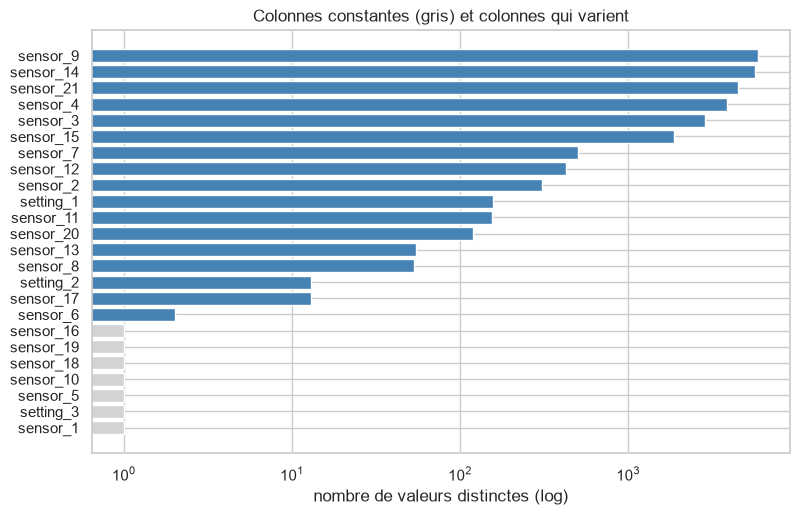

In [6]:
measure_columns = COLUMN_NAMES[2:]
n_unique = analysis_df[measure_columns].nunique().sort_values()
constant_columns = [c for c in measure_columns if n_unique[c] == 1]
print("Colonnes constantes :", constant_columns)
print("sensor_6 (en %) :", (analysis_df["sensor_6"].value_counts(normalize=True) * 100).round(1).to_dict())
print("Écart-type setting_1 / setting_2 :", analysis_df[["setting_1", "setting_2"]].std().round(4).to_dict())

fig, ax = plt.subplots(figsize=(9, 5.5))
ax.barh(n_unique.index, n_unique.values, color=["lightgray" if n == 1 else "steelblue" for n in n_unique])
ax.set_xscale("log")
ax.set(xlabel="nombre de valeurs distinctes (log)", title="Colonnes constantes (gris) et colonnes qui varient")
save(fig, "02_valeurs_distinctes.png")

**Décision.** 7 colonnes constantes sont écartées (`setting_3`, `sensor_1`, `5`, `10`, `16`, `18`, `19`). `sensor_6` ne prend que deux valeurs (98 % / 2 %) et est aussi écarté. `setting_1` et `setting_2` varient très peu autour de 0 (FD001 a une seule condition de fonctionnement) : la section 9 confirme qu'ils n'ont pas de lien avec le RUL.

**14 capteurs sont retenus.**

14 capteurs : ['sensor_2', 'sensor_3', 'sensor_4', 'sensor_7', 'sensor_8', 'sensor_9', 'sensor_11', 'sensor_12', 'sensor_13', 'sensor_14', 'sensor_15', 'sensor_17', 'sensor_20', 'sensor_21']


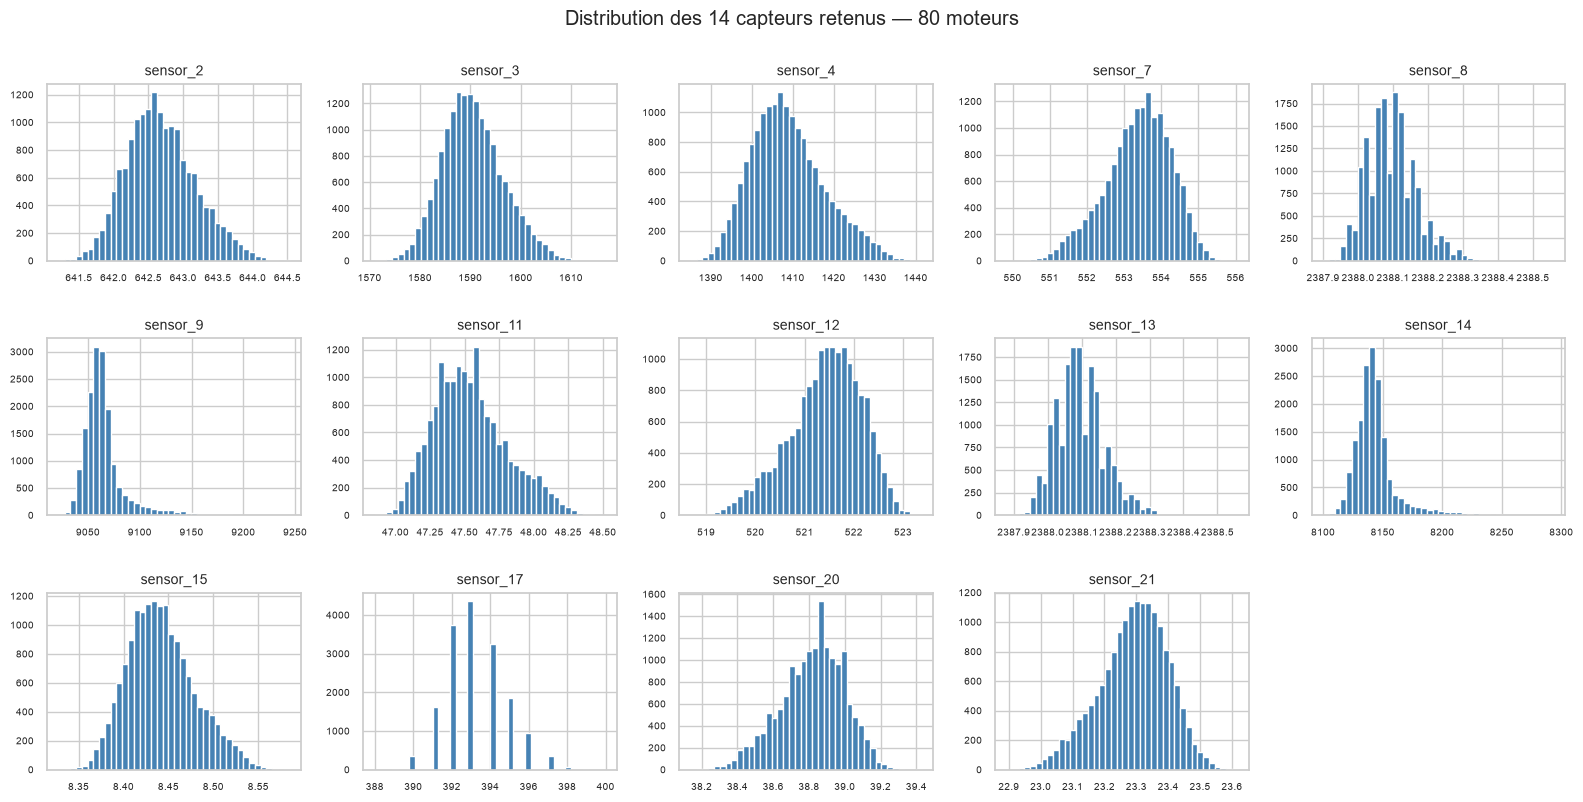

sensor_12   -0.47
sensor_7    -0.41
sensor_20   -0.38
sensor_21   -0.37
sensor_3     0.32
sensor_2     0.34
sensor_17    0.37
sensor_15    0.41
sensor_4     0.47
sensor_11    0.49
sensor_13    0.52
sensor_8     0.53
sensor_14    2.43
sensor_9     2.61
dtype: float64

In [7]:
SELECTED_SENSORS = [s for s in COLUMN_NAMES if s.startswith("sensor") and s not in constant_columns and s != "sensor_6"]
EXCLUDED_COLUMNS = ["sensor_6", "setting_1", "setting_2"]
print(len(SELECTED_SENSORS), "capteurs :", SELECTED_SENSORS)

fig, axes = plt.subplots(3, 5, figsize=(16, 8))
for ax, sensor in zip(axes.ravel(), SELECTED_SENSORS):
    ax.hist(analysis_df[sensor], bins=40, color="steelblue")
    ax.set_title(sensor, fontsize=10)
    ax.tick_params(labelsize=7)
axes.ravel()[-1].axis("off")
fig.suptitle("Distribution des 14 capteurs retenus — 80 moteurs", y=1.0)
fig.tight_layout()
save(fig, "03_distributions_capteurs.png")
analysis_df[SELECTED_SENSORS].skew().round(2).sort_values()

**Interprétation.** Les distributions sont unimodales, sans valeur aberrante isolée. `sensor_9` et `sensor_14` ont une longue queue à droite (asymétrie > 2) : une partie des moteurs atteint des valeurs élevées en fin de vie (section 8). `sensor_17` ne prend que des valeurs entières et `sensor_8` / `sensor_13` sont fortement quantifiés : ce sont des mesures discrètes, d'où l'intérêt de les lisser sur plusieurs cycles.
Les échelles des capteurs sont très différentes : sans effet sur la régression linéaire et la forêt, mais Ridge devra normaliser ses entrées.

## 7. Cible RUL

Dans le train, chaque moteur est suivi jusqu'à la panne : si la panne a lieu au cycle $T$, alors au cycle $t$, $RUL = T - t$ (calcul par `add_rul`, vérifié par les tests).
Le dernier cycle $T$ n'est jamais gardé comme entrée : il révèle la date de la panne.

**RUL plafonné.** En début de vie, les capteurs ne bougent presque pas : distinguer 250 de 300 cycles restants est impossible. On peut entraîner sur `min(RUL, plafond)`. La valeur du plafond sera **choisie par validation croisée** en S3 ; 125 n'est ici qu'une illustration.

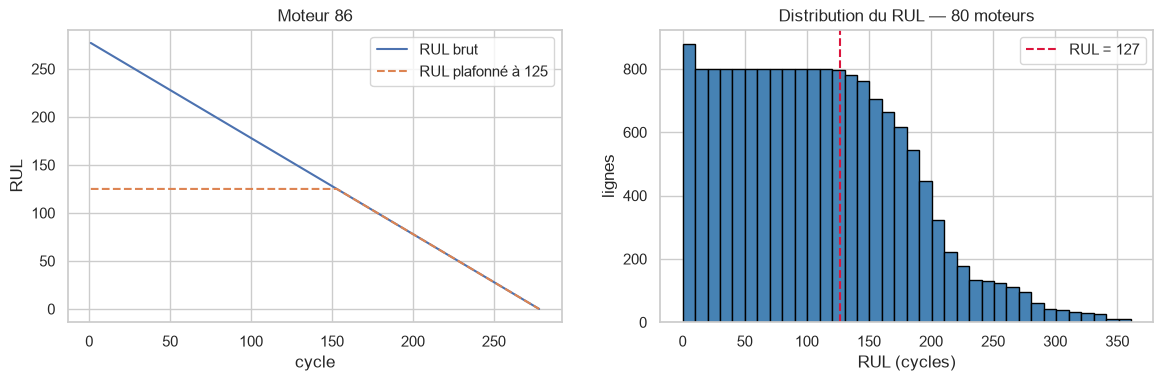

Zone d'évaluation : RUL <= 127 - 61.8 % des lignes


In [8]:
assert (analysis_df.groupby("unit_id")["RUL"].min() == 0).all() and (analysis_df["RUL"] >= 0).all()

engine = analysis_df[analysis_df["unit_id"] == 86]
fig, axes = plt.subplots(1, 2, figsize=(14, 3.8))
axes[0].plot(engine["cycle"], engine["RUL"], label="RUL brut")
axes[0].plot(engine["cycle"], engine["RUL"].clip(upper=125), "--", label="RUL plafonné à 125")
axes[0].set(xlabel="cycle", ylabel="RUL", title="Moteur 86")
axes[0].legend()

EVAL_HORIZON = int(train_lengths[train_engines].min()) - 1      # tous les moteurs couvrent RUL = 0 .. EVAL_HORIZON
axes[1].hist(analysis_df["RUL"], bins=36, color="steelblue", edgecolor="black")
axes[1].axvline(EVAL_HORIZON, color="crimson", linestyle="--", label=f"RUL = {EVAL_HORIZON}")
axes[1].set(xlabel="RUL (cycles)", ylabel="lignes", title="Distribution du RUL — 80 moteurs")
axes[1].legend()
save(fig, "04_rul.png")
print("Zone d'évaluation : RUL <=", EVAL_HORIZON, "-", round((analysis_df["RUL"] <= EVAL_HORIZON).mean() * 100, 1), "% des lignes")

**Interprétation.** L'histogramme est plat de 0 à 127 puis décroît : le moteur d'entraînement le plus court vit 128 cycles, donc chaque moteur fournit exactement une ligne pour chaque RUL de 0 à 127.
La zone **RUL ≤ 127** est donc couverte de façon équilibrée et correspond à la période où la maintenance doit agir : la baseline sera évaluée sur cette zone.

## 8. Évolution des capteurs avant la panne

Courbe de chaque moteur en fonction du RUL (panne à droite), lissée par une moyenne glissante **causale** sur 10 cycles (passé uniquement).

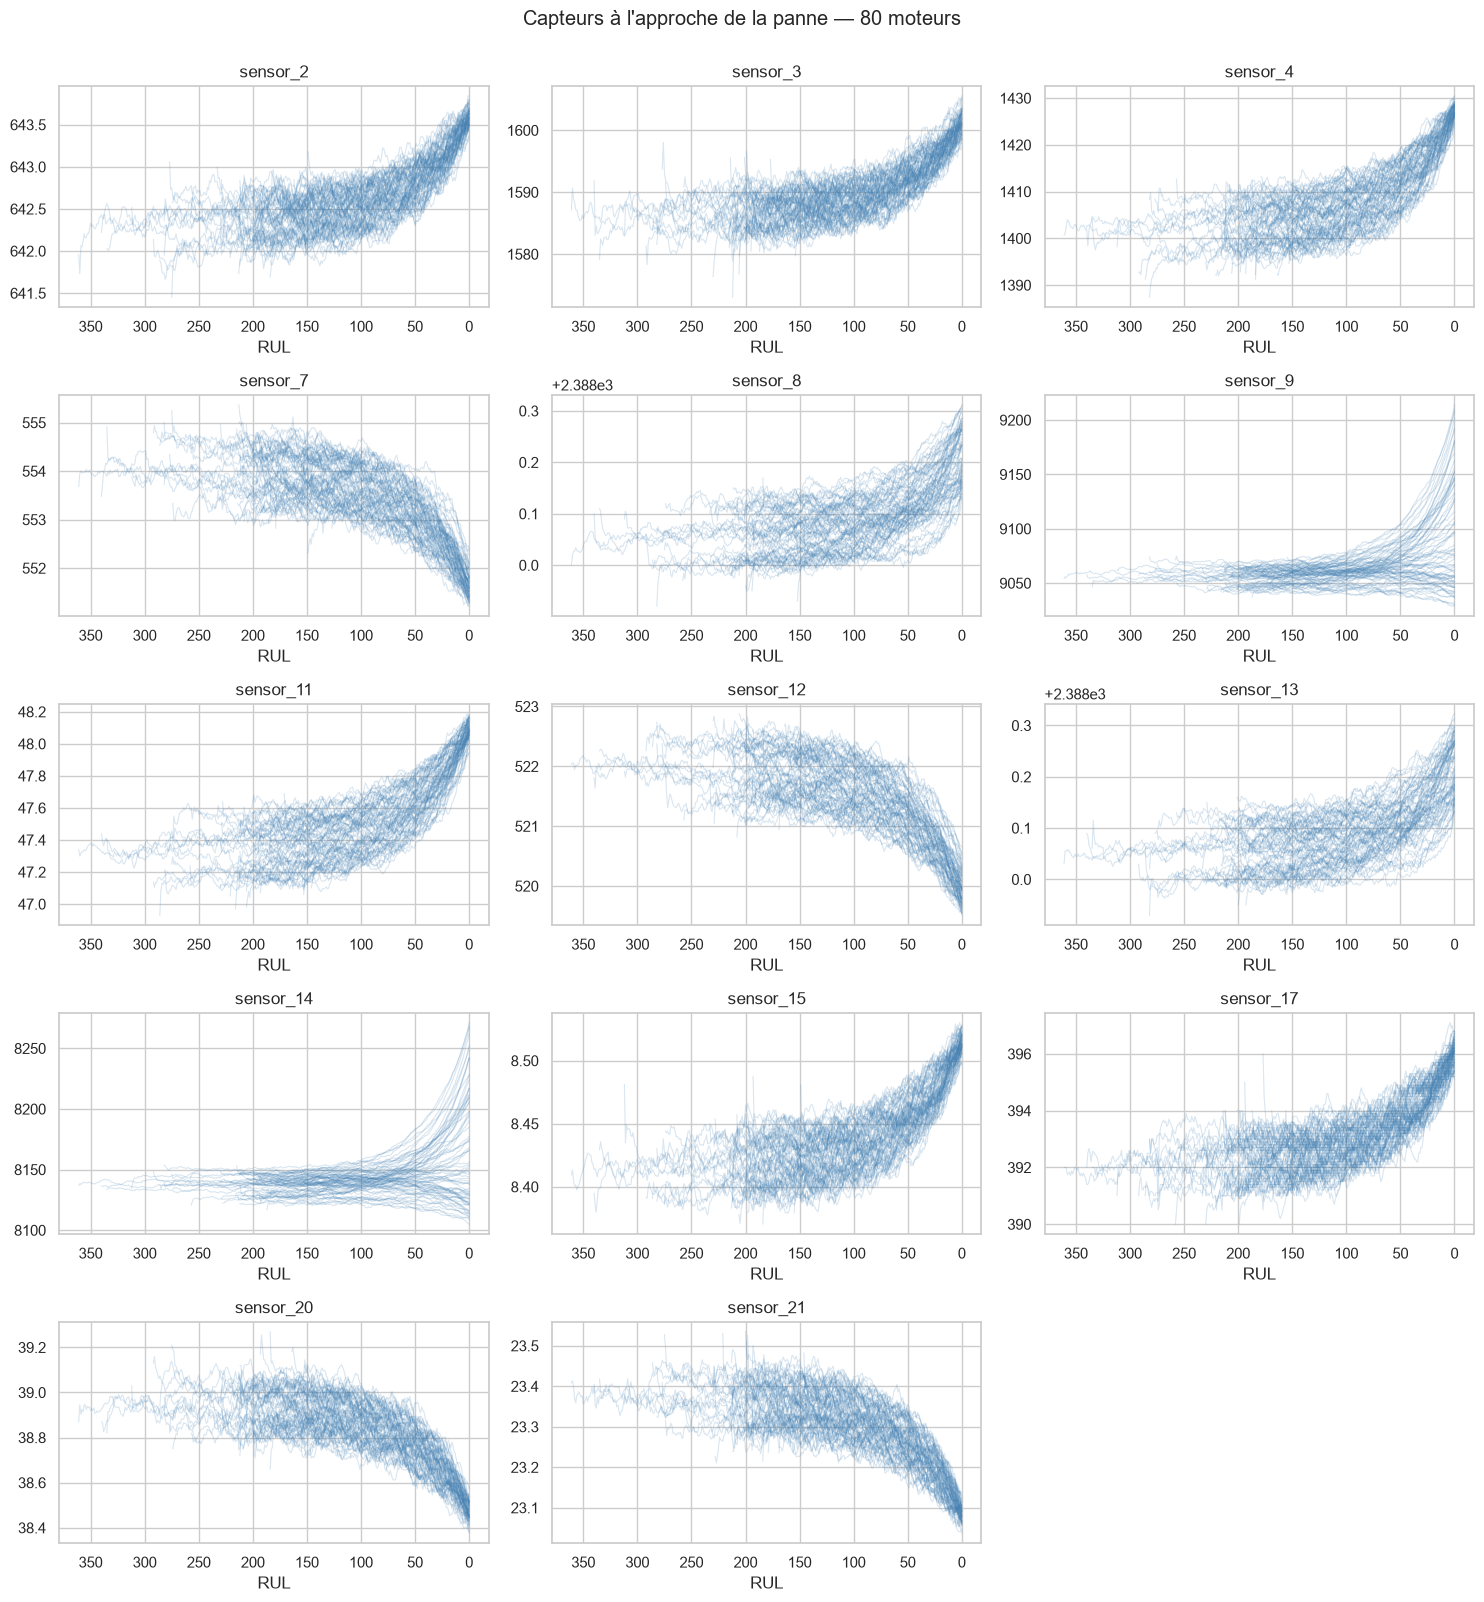

In [9]:
fig, axes = plt.subplots(5, 3, figsize=(15, 16))
for ax, sensor in zip(axes.ravel(), SELECTED_SENSORS):
    for _, engine in analysis_df.groupby("unit_id"):
        ax.plot(engine["RUL"], engine[sensor].rolling(10, min_periods=1).mean(), color="steelblue", alpha=0.2, lw=0.8)
    ax.invert_xaxis()
    ax.set(title=sensor, xlabel="RUL")
axes.ravel()[-1].axis("off")
fig.suptitle("Capteurs à l'approche de la panne — 80 moteurs", y=1.0)
fig.tight_layout()
save(fig, "05_capteurs_vs_rul.png")

**Interprétation.**
- 12 capteurs évoluent nettement vers la panne : 8 augmentent (`sensor_2`, `3`, `4`, `8`, `11`, `13`, `15`, `17`) et 4 diminuent (`sensor_7`, `12`, `20`, `21`).
- La dégradation est **lente puis accélérée** : plateau en début de vie, puis variation rapide sur les 100 à 150 derniers cycles. Cela justifie le RUL plafonné.
- Chaque moteur part d'un **niveau différent** : l'écart au début de vie du moteur sera plus informatif qu'une mesure brute.
- `sensor_9` et `sensor_14` ont deux comportements selon les moteurs (forte hausse ou légère baisse en fin de vie).

Conséquence pour la baseline : donner au modèle l'**historique récent** (moyenne, tendance, écart au départ) plutôt qu'une mesure isolée et bruitée.

## 9. Corrélations avec le RUL

Pearson mesure un lien linéaire, Spearman un lien monotone. Une corrélation **négative** signifie que le capteur augmente quand la panne approche.

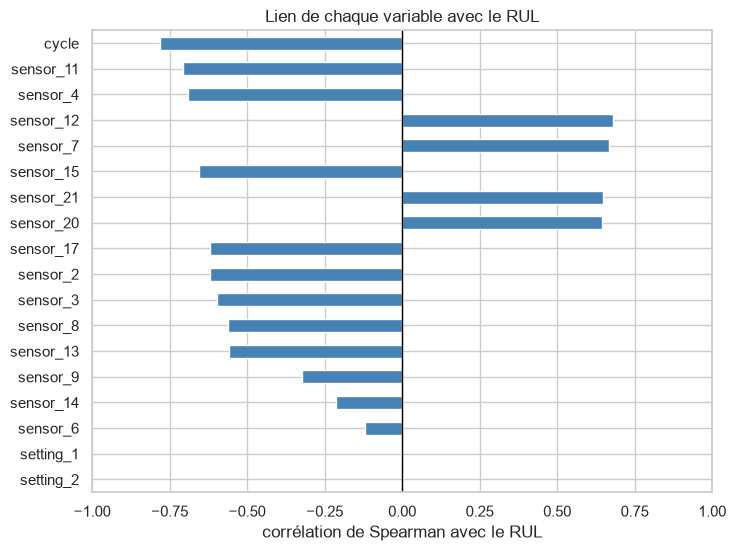

,cycle,sensor_11,sensor_4,sensor_12,sensor_7,sensor_15,sensor_21,sensor_20,sensor_17,sensor_2,sensor_3,sensor_8,sensor_13,sensor_9,sensor_14,sensor_6,setting_1,setting_2
pearson,-0.72,-0.68,-0.67,0.66,0.64,-0.63,0.62,0.62,-0.60,-0.60,-0.58,-0.55,-0.55,-0.39,-0.31,-0.12,-0.01,0.01
spearman,-0.78,-0.71,-0.69,0.68,0.67,-0.66,0.65,0.65,-0.62,-0.62,-0.60,-0.56,-0.56,-0.32,-0.21,-0.12,-0.00,0.00


In [10]:
variables = ["cycle"] + SELECTED_SENSORS + EXCLUDED_COLUMNS
correlations = pd.DataFrame({
    "pearson": analysis_df[variables].corrwith(analysis_df["RUL"], method="pearson"),
    "spearman": analysis_df[variables].corrwith(analysis_df["RUL"], method="spearman"),
})
correlations = correlations.loc[correlations["spearman"].abs().sort_values(ascending=False).index]

fig, ax = plt.subplots(figsize=(8, 6))
correlations["spearman"].iloc[::-1].plot.barh(ax=ax, color="steelblue")
ax.axvline(0, color="black", lw=1)
ax.set(xlim=(-1, 1), xlabel="corrélation de Spearman avec le RUL", title="Lien de chaque variable avec le RUL")
save(fig, "06_correlations_rul.png")
correlations.round(2).T

**Interprétation.**
- 12 capteurs ont un lien net avec le RUL (|Spearman| de 0,56 à 0,71 ; le plus fort : `sensor_11`). Spearman est en général supérieur à Pearson : le lien est monotone mais non linéaire.
- `sensor_9` et `sensor_14` ont un lien faible (−0,32 et −0,21) à cause de leur double comportement. Ils sont **gardés** : un modèle non linéaire peut exploiter leur comportement en fin de vie, et la baseline le vérifiera.
- `sensor_6`, `setting_1` et `setting_2` n'ont aucun lien (|Spearman| < 0,12) : leur exclusion est confirmée.
- `cycle` (−0,78) est lié mécaniquement au RUL. Il n'est **pas** utilisé comme entrée : le modèle doit estimer l'état du moteur à partir des capteurs, pas son âge.

Une corrélation est une piste, pas une preuve d'utilité : seule la validation tranchera.

## 10. Redondance entre capteurs

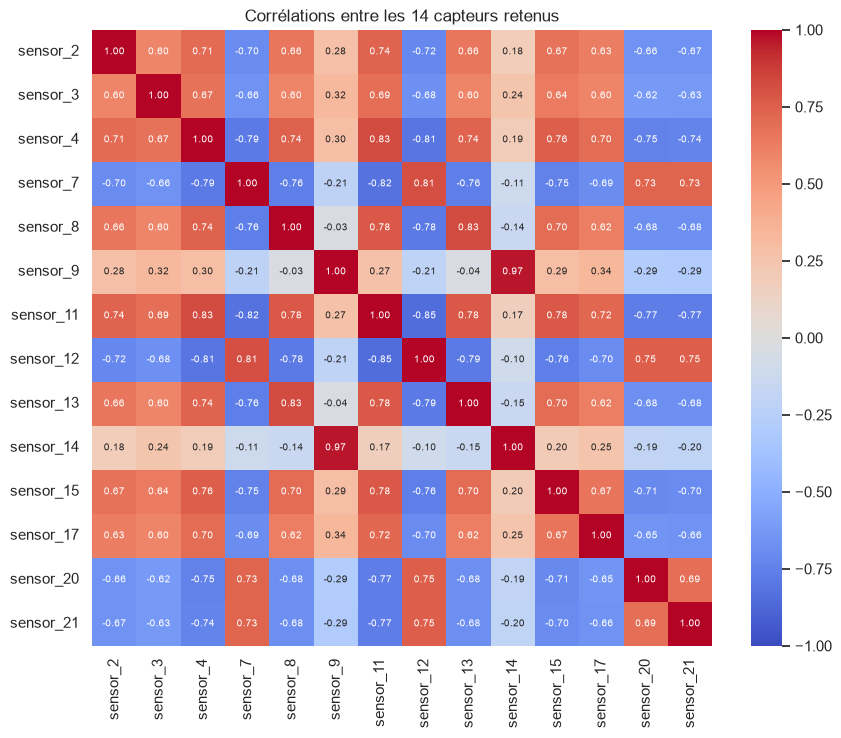

,capteur_1,capteur_2,corrélation
5,sensor_9,sensor_14,0.97
6,sensor_11,sensor_12,-0.85
0,sensor_4,sensor_11,0.83
4,sensor_8,sensor_13,0.83
2,sensor_7,sensor_11,-0.82
1,sensor_4,sensor_12,-0.81
3,sensor_7,sensor_12,0.81


In [11]:
sensor_corr = analysis_df[SELECTED_SENSORS].corr()
fig, ax = plt.subplots(figsize=(10, 8))
sns.heatmap(sensor_corr, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, ax=ax, annot_kws={"size": 7})
ax.set_title("Corrélations entre les 14 capteurs retenus")
save(fig, "07_matrice_correlation.png")

pairs = [{"capteur_1": a, "capteur_2": b, "corrélation": round(float(sensor_corr.loc[a, b]), 2)}
         for i, a in enumerate(SELECTED_SENSORS) for b in SELECTED_SENSORS[i + 1:]
         if abs(sensor_corr.loc[a, b]) >= 0.80]
redundant_pairs = pd.DataFrame(pairs).sort_values("corrélation", key=abs, ascending=False)
redundant_pairs

**Interprétation.** 7 paires dépassent 0,80 en valeur absolue, la plus forte étant `sensor_9` / `sensor_14` (0,97). Une partie de cette redondance vient simplement du fait que ces capteurs suivent tous la même dégradation.
Les 14 capteurs sont gardés : la forêt aléatoire supporte la redondance ; pour la régression linéaire, elle rend les coefficients instables sans dégrader les prédictions. C'est précisément ce que la régression **Ridge** (régularisée) permettra de vérifier en S3.

## 11. Contrôle des entrées du jeu de test

Seules les **entrées** du test sont examinées (pas son RUL réel) : combien d'historique est disponible au dernier cycle observé ?

Valeurs manquantes : 0 - doublons : 0
Cycles observés : {'count': 100.0, 'mean': 131.0, 'std': 53.6, 'min': 31.0, '25%': 88.8, '50%': 133.5, '75%': 164.2, 'max': 303.0}
Moteurs avec < 30 cycles : 0 - avec < 50 cycles : 7
Colonnes constantes du train, valeurs distinctes dans le test : {'setting_3': 1, 'sensor_1': 1, 'sensor_5': 1, 'sensor_10': 1, 'sensor_16': 1, 'sensor_18': 1, 'sensor_19': 1}


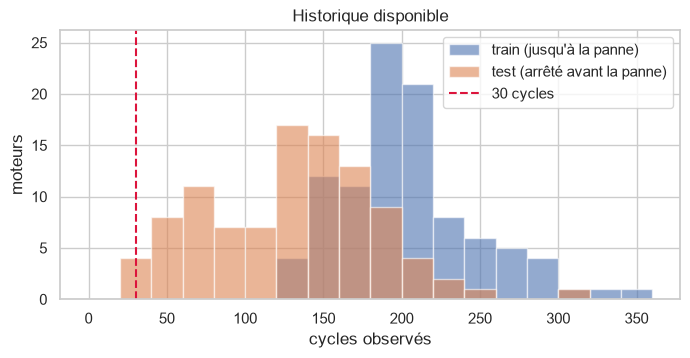

In [12]:
test_lengths = test_df.groupby("unit_id")["cycle"].max()
print("Valeurs manquantes :", int(test_df.isna().sum().sum()), "- doublons :", int(test_df.duplicated().sum()))
print("Cycles observés :", test_lengths.describe().round(1).to_dict())
print("Moteurs avec < 30 cycles :", int((test_lengths < 30).sum()), "- avec < 50 cycles :", int((test_lengths < 50).sum()))
print("Colonnes constantes du train, valeurs distinctes dans le test :", test_df[constant_columns].nunique().to_dict())

fig, ax = plt.subplots(figsize=(8, 3.5))
bins = range(0, 380, 20)
ax.hist(train_lengths, bins=bins, alpha=0.6, label="train (jusqu'à la panne)")
ax.hist(test_lengths, bins=bins, alpha=0.6, label="test (arrêté avant la panne)")
ax.axvline(30, color="crimson", linestyle="--", label="30 cycles")
ax.set(xlabel="cycles observés", ylabel="moteurs", title="Historique disponible")
ax.legend()
save(fig, "08_historique_test.png")

HISTORY_WINDOW = 30

**Décision.** Les moteurs de test ont entre 31 et 303 cycles observés ; 7 en ont moins de 50. Une fenêtre d'historique de **30 cycles** est donc utilisable pour tous les moteurs de test, sans cas particulier.

## 12. Export des décisions pour la baseline

| Règle transmise à S3 | Raison |
|---|---|
| Séparer par moteur (80 / 20) | les cycles d'un même moteur se ressemblent |
| Jamais `unit_id`, `cycle`, dernier cycle ou % de vie en entrée | identité du moteur ou date de la panne |
| Features calculées avec le passé uniquement | en exploitation, le futur n'existe pas |
| Choix par validation sur l'entraînement, jamais sur le test | sinon le score final est optimiste |

In [13]:
exports = {
    "fd001_engine_split.json": {
        "dataset": "FD001", "random_state": RANDOM_STATE,
        "method": "permutation des 100 moteurs (graine 42), 20 premiers = validation",
        "train_engines": train_engines, "validation_engines": validation_engines,
    },
    "fd001_feature_groups.json": {
        "constant_columns": constant_columns, "excluded_columns": EXCLUDED_COLUMNS,
        "selected_sensors": SELECTED_SENSORS, "redundant_pairs": redundant_pairs.to_dict("records"),
        "forbidden_as_feature": ["unit_id", "cycle", "RUL", "last_cycle", "life_pct"],
    },
    "eda_fd001_summary.json": {
        "raw_files_sha256": sha256, "train_rows": len(train_df), "test_rows": len(test_df),
        "train_length_min_max": [int(train_lengths.min()), int(train_lengths.max())],
        "test_length_min_max": [int(test_lengths.min()), int(test_lengths.max())],
        "evaluation_horizon": EVAL_HORIZON, "history_window": HISTORY_WINDOW,
    },
}
for filename, content in exports.items():
    (OUT_DIR / filename).write_text(json.dumps(content, indent=2, ensure_ascii=False), encoding="utf-8")
    print("Enregistré :", filename)

Enregistré : fd001_engine_split.json
Enregistré : fd001_feature_groups.json
Enregistré : eda_fd001_summary.json


## 13. Conclusion

- Données propres : aucune valeur manquante, aucun doublon, cycles continus. Durées de vie de 128 à 362 cycles.
- **14 capteurs retenus** ; 7 colonnes constantes, `sensor_6`, `setting_1` et `setting_2` écartés.
- Dégradation lente puis accélérée, niveau de départ propre à chaque moteur → features d'historique et RUL plafonné à tester en S3.
- Séparation **80 / 20 moteurs**, zone d'évaluation **RUL ≤ 127**, historique de **30 cycles**.

**Limites.** Données simulées, une seule condition de fonctionnement et un seul mode de panne, seulement 20 moteurs de validation.

La cellule suivante vérifie que les chiffres cités dans ce notebook correspondent à l'exécution.

In [14]:
assert len(train_df) == 20631 and len(test_df) == 13096
assert set(quality.values()) == {0}
assert (train_lengths.min(), train_lengths.max(), train_lengths.median()) == (128, 362, 199)
assert len(analysis_df) == 16561 and len(validation_df) == 4070
assert train_lengths[validation_engines].max() == 269 and train_lengths[validation_engines].median() == 193.5
assert len(constant_columns) == 7 and len(SELECTED_SENSORS) == 14 and EVAL_HORIZON == 127
spearman = correlations["spearman"]
twelve = [s for s in SELECTED_SENSORS if s not in ("sensor_9", "sensor_14")]
assert spearman[twelve].abs().round(2).between(0.56, 0.71).all() and spearman[twelve].abs().idxmax() == "sensor_11"
assert round(spearman["sensor_9"], 2) == -0.32 and round(spearman["sensor_14"], 2) == -0.21
assert spearman[EXCLUDED_COLUMNS].abs().max() < 0.12 and round(spearman["cycle"], 2) == -0.78
assert len(redundant_pairs) == 7 and redundant_pairs.iloc[0]["corrélation"] == 0.97
assert (test_lengths.min(), test_lengths.max()) == (31, 303) and (test_lengths < 50).sum() == 7
print("Chiffres cités vérifiés.")

Chiffres cités vérifiés.
